In [120]:
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.cluster import KMeans  # noqa: E402
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,  # noqa: E402
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.compose import ColumnTransformer

from IPython.display import display

from nutriscope.classification import KEY_NUTRIENTS
from nutriscope.options import RANDOM_SEED as SEED
from nutriscope.figures import figure
from kneed import KneeLocator


pd.set_option("display.precision", 3)

In [121]:
df = pd.read_parquet("../data-nutriscope/nutriscope_ml_sample.parquet")

In [122]:
df_grouped = df.groupby("pnns_groups_1")

In [123]:
PNNS_TARGET = "Beverages"
Z = df_grouped.get_group(PNNS_TARGET)[KEY_NUTRIENTS]

In [124]:
preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), KEY_NUTRIENTS)
])

In [125]:
lines = []
labels = {}
k_range = range(2, 13)
for k in k_range:
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("kmean", KMeans(n_clusters=k, n_init=10, random_state=SEED))
    ])
    pipeline.fit(Z)
    Z_scaled = pipeline.named_steps["preprocessor"].fit_transform(Z)
    km = pipeline.named_steps["kmean"]
    labels[k] = km.labels_
    lines.append({
        "k": k,
        "inertie": int(km.inertia_),
        "silhouette": round(float(silhouette_score(Z_scaled, km.labels_,
                                                    sample_size=10000,
                                                    random_state=SEED)), 4),
        "davies_bouldin": round(float(davies_bouldin_score(Z_scaled, km.labels_)), 3),
        "calinski": int(calinski_harabasz_score(Z_scaled, km.labels_)),
        "plus petit groupe": int(np.bincount(km.labels_).min()),
    })
bal = pd.DataFrame(lines).set_index("k")
bal.insert(1, "gain %", (100 * (bal["inertie"].shift(1) - bal["inertie"])
                            / bal["inertie"].shift(1)).round(1))
aff = bal.copy()
aff["inertie"] = aff["inertie"].map(lambda v: f"{v}")
aff["gain %"] = aff["gain %"].map(lambda v: "" if pd.isna(v) else f"{v:.1f}")
aff["silhouette"] = aff["silhouette"].map(lambda v: f"{v:.4f}")
display(aff)

,inertie,gain %,silhouette,davies_bouldin,calinski,plus petit groupe
k,,,,,,
2,9918,,0.8527,1.069,1285,111
3,7229,27.1,0.8571,0.882,1295,55
4,5583,22.8,0.8614,0.836,1336,5
5,4074,27.0,0.8694,0.688,1579,5
6,3402,16.5,0.4889,0.755,1600,5
7,3005,11.7,0.4905,0.795,1558,5
8,2615,13.0,0.4918,0.765,1581,2
9,2288,12.5,0.4975,0.710,1621,2
10,2030,11.3,0.5392,0.762,1654,2


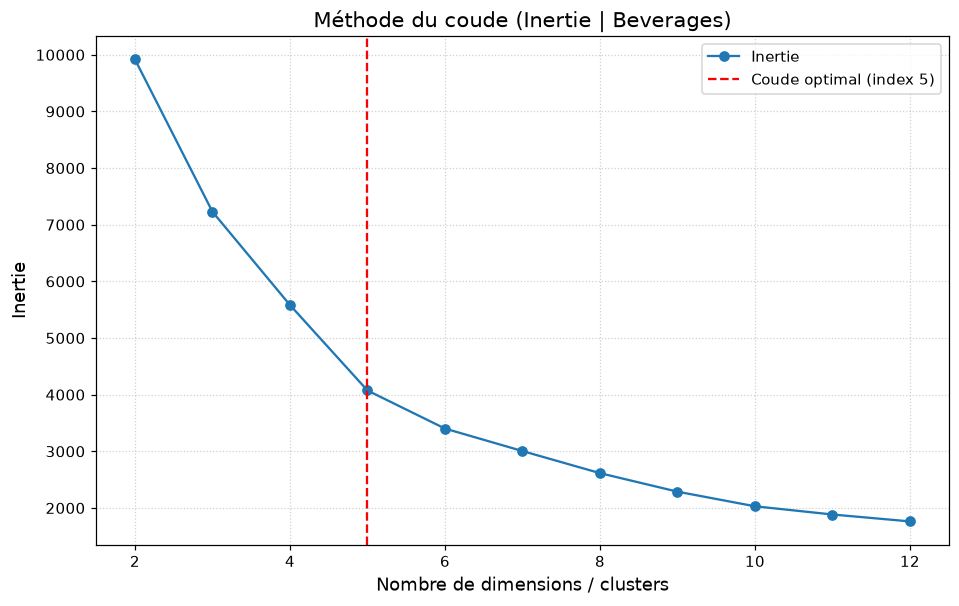

WindowsPath('C:/Users/Administrateur/Documents/Cours/NutriScope - Projet/Nutriscope_team_delegue/notebooks/figures/coude-inertie.png')

In [126]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(bal["inertie"], marker="o", label="Inertie")

# x = nombre de clusters, y = bal["inertie"]
kneedle = KneeLocator(k_range, bal["inertie"], 
                      curve="convex", direction="decreasing")

optimal_k = kneedle.elbow

y_val = bal["inertie"].iloc[optimal_k]
ax.axvline(x=optimal_k, color='red', linestyle='--', label=f'Coude optimal (index {optimal_k})')

ax.set_title(f"Méthode du coude (Inertie | {PNNS_TARGET})", fontsize=14)
ax.set_xlabel("Nombre de dimensions / clusters", fontsize=12)
ax.set_ylabel("Inertie", fontsize=12)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)

figure(fig, "coude-inertie")

C:\Users\Administrateur\AppData\Local\Temp\ipykernel_20004\1085074303.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


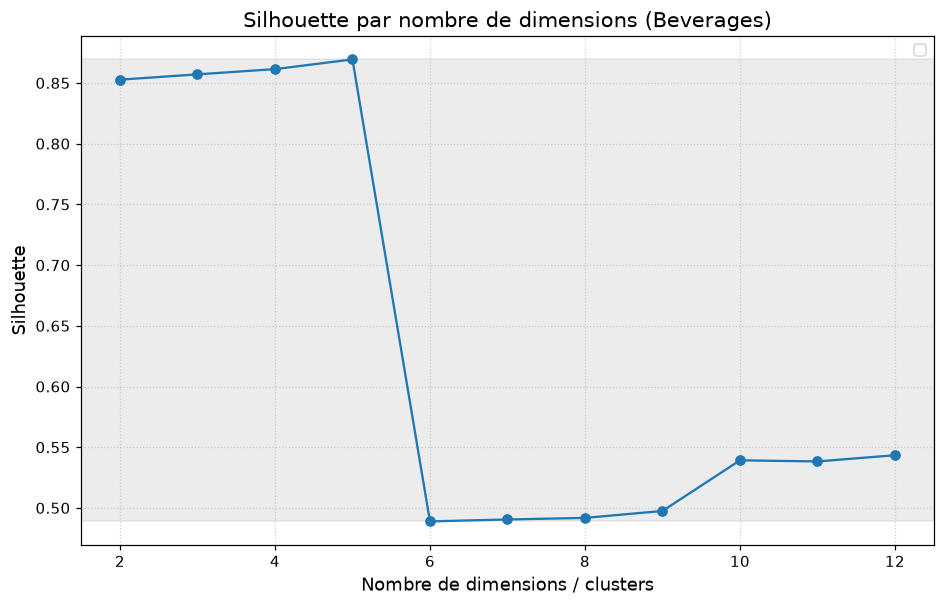

WindowsPath('C:/Users/Administrateur/Documents/Cours/NutriScope - Projet/Nutriscope_team_delegue/notebooks/figures/silhouette.png')

In [127]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(bal["silhouette"], marker="o")

limit_min = bal["silhouette"].min()
limit_max = bal["silhouette"].max()
x_window = ax.get_xlim()
ax.fill_between(x_window, limit_max, limit_min, color="grey", alpha=0.15,)
ax.set_xlim(*x_window)
ax.set_title(f"Silhouette par nombre de dimensions ({PNNS_TARGET})", fontsize=14)
ax.set_xlabel("Nombre de dimensions / clusters", fontsize=12)
ax.set_ylabel("Silhouette", fontsize=12)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)

figure(fig, "silhouette")

L'analyse des métriques de validation pour `k` variant de 2 à 12 oriente vers `k = 5` :
- Stabilité (de `k=2` à `4`) : La silhouette reste élevée ($\approx 0,85$), mais le découpage reste trop macroscopique.
Le point optimal (`k=5`)
Il offre le meilleur compromis statistique et métier :
- L'indice de Davies-Bouldin atteint son minimum optimal (`0,688`), garantissant une compacité maximale.La silhouette se maintient solidement à `0,694`.
- La rupture (`k` $\ge 6$) : Une chute brutale de la silhouette (< 0,48) confirme qu'au-delà de 5 clusters, on tombe dans le sur-découpage artificiel.

En résumé : `k=5` permet d'isoler finement les profils spécifiques (sirops, bouillons salés, boissons protéinées ou grasses) sans dégrader la cohérence mathématique des groupes.

In [129]:
K_CHOSEN = 5
labeled_Z = Z.copy()
labeled_Z["label"] = labels[K_CHOSEN]
grouped_labeled_Z = labeled_Z.groupby("label")
print("\nsize\n")
display(pd.DataFrame({"n": grouped_labeled_Z.size()}))
print("\nmean\n")
display(grouped_labeled_Z.mean())
print("\nstd\n")
display(grouped_labeled_Z.std())
print("\n5 premiers\n")
for label, group in grouped_labeled_Z:
    print(label)
    display(df.iloc[group.index][["product_name", "pnns_groups_2"]].head())


size



,n
label,
0,2116
1,48
2,5
3,23
4,41



mean



,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g
label,,,,,,,
0,32.847,0.326,0.114,6.979,6.284,0.411,0.054
1,313.755,1.458,1.267,79.177,72.563,0.749,0.163
2,41.042,0.525,0.087,8.565,7.764,0.302,16.506
3,322.247,7.404,3.457,42.570,15.700,19.357,0.462
4,256.161,21.629,16.050,15.383,7.850,2.778,0.409



std



...

,product_name,pnns_groups_2
243,Grape Flavored Juice Drink from Concentrate,Sweetened beverages
2025,Organic Cashewmilk,Plant-based milk substitutes
5569,"Nectar Orange Pêche Et Abricot, 2 Litres, Marq...",Fruit juices
28703,Jugo de mango,Fruit juices
30008,Minuman Laici (Lychee drink),Sweetened beverages


3


,product_name,pnns_groups_2
148,matcha,Teas and herbal teas and coffees
2778,Dosette café au lait,Teas and herbal teas and coffees
5905,"Café Au Lait,",Unsweetened beverages
7805,Cacao maigre en poudre,Unsweetened beverages
9316,Préparation instantanée pour boisson au café e...,Sweetened beverages


4


,product_name,pnns_groups_2
60,Lait de coco,Plant-based milk substitutes
287,Caramel Latte,Plant-based milk substitutes
596,NaN,Sweetened beverages
1349,Lait de coco,Plant-based milk substitutes
1839,Lait de coco,Plant-based milk substitutes


0. Cluster 0 $\rightarrow$ Les Boissons de rafraîchissement standard / Prêtes à boire
1. Cluster 1 $\rightarrow$ Concentrés et sirops ultra-glucidiques
2. Cluster 2 $\rightarrow$ Les Boissons salées / atypiques (Micro-groupe)
3. Cluster 3 $\rightarrow$ Les Boissons riches en protéines / lactées
4. Cluster 3 $\rightarrow$ Les Boissons riches en lipides / émulsions végétales